# How tuning sharpens a code model's algorithm choice: the B2 patching analysis

This notebook demonstrates one claim (**B2**) of the iteration-9 experiment *"where instruction tuning sharpened the
algorithm choice"* (claims B1-B3).

**Question.** Does an LLM give *the mean answer*? Asked to write code, an instruction-tuned model nearly always picks
the same algorithm, for example Kruskal for a minimum spanning tree. The study looks at the **fork**, the single
token position where the model commits to an algorithm, and compares an instruction-tuned model with its base model
on **identical token ids**:

* **B1** (behavioural, Gemma-3-4b pt/it and Llama-3.1-8B base/instruct): the instruct model is much sharper at the fork
  than its base, but the divergence there is about what any high-entropy base position shows. Verdict PARTIAL.
* **B2** (mechanistic, Qwen3-8B vs Qwen3-8B-Base, *this notebook*): which components carry the sharpening? The base
  model's outputs of a component set *X* are patched into the instruct run at the fork (cross-model activation
  patching, CMAP), and the analysis measures how much of the instruct-minus-base gap closes.
* **B3**: rerun of an iteration-8 held-out check that a `MeanCache` bug had silently disabled.

**Quantities** (definitions from `src/cfg9.py`):

* **Units.** B2 has two task units: `B3`, a minimum spanning tree task, and `T10`, a connected-components task.
  The ids are task names carried over from earlier iterations; unit `B3` is unrelated to claim B3.
* **Margin** m = log P(D) − log P(A) at the fork. D is the instruct model's default algorithm class and A is the
  alternative. On `B3`, D starts with ` Kr`(uskal), ` Union`, … and A with ` Prim`, … On `T10`, D is ` find`
  (union-find) and A is ` dfs` / ` bfs`.
* **share(X)** = Σ_p (m_I − m_X) / Σ_p (m_I − m_B) over prompts p. It is the fraction of the instruct-minus-base
  gap that closes when the base outputs of X replace the instruct ones at the fork. A share of 1 means X alone turns
  the instruct model into its base at this token; 0 means no effect.
* **FSTACK**: 10 "fork-stack" nodes validated in iteration 8 (MLPs of layers 26, 27, 28, 30, 32 and 5 attention
  heads). **SPEC**: task-specification nodes upstream. **R / R-pure / R-scaled**: 50 random late-layer sets matched
  to FSTACK's write norms (the null). **RS-fork(l)**: swapping the whole residual stream at layer l (an upper bound).
  **REV**: instruct outputs patched into the base run.

**Pre-registered rules** (sha256 commitment chain): Q1, FSTACK share ≥ 0.5 on both units; Q2, FSTACK above the 95th
percentile of the matched random sets, with the random median ≤ 0.15; Q3, SPEC share ≤ 0.15. If all three hold the
verdict is SUPPORTED, if FSTACK ≤ 0.2 on both units it is DISCONFIRMED, and otherwise it is PARTIAL.

**What runs here.** The GPU stages (Qwen3-8B and Qwen3-8B-Base forward passes with patching hooks, roughly 32 GB of
weights; the whole experiment took about one GPU-hour on an L4) cannot run in a notebook. Their per-prompt output is the margin of each of
**1,429 patching arms** for 20 prompts × 2 units. It is loaded from `mini_demo_data.json`, and everything downstream
of it is the artifact's own code, copied from `src/` and run here:

1. the stage map of `method.py`;
2. the CPU part of the GPU stage `cache_qwen`: re-drawing the write-norm-matched random sets (`src/cmap9.py`) and
   checking that they are exactly the sets that were patched;
3. the committed B2 analysis (`src/analysis9.py` with `src/stats9.py`): shares, bootstrap CIs, random nulls,
   Q1-Q3, the verdict and the localisation rule;
4. the independent standard-library re-derivation with placebos (`src/rederive9.py`);
5. figures F3-F5 (`src/figures9.py`), followed by a comparison with the full run's reported numbers.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru — NOT on Colab, always install (the artifact logs every stage with it)
_pip('loguru==0.7.3')

# numpy, pandas, matplotlib — pre-installed on Colab, install locally only
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'pandas==2.2.2', 'matplotlib==3.10.0')

In [2]:
from __future__ import annotations

# --- method.py
import argparse
import subprocess
import sys
import time
from pathlib import Path

from loguru import logger

# --- src/cfg9.py
import hashlib
import json
import math
import os
import resource
from datetime import datetime, timezone
from typing import Any, Iterable

import numpy as np

# --- src/stats9.py
import itertools
from typing import Sequence

# --- src/cmap9.py (torch is only needed by its GPU stages, which this notebook does not run)
import gc

# --- src/rederive9.py (standard library only)
import random
import statistics

# --- src/figures9.py: matplotlib.use("Agg") is dropped so the figures render inline; torch is only used by F8
import matplotlib
import matplotlib.pyplot as plt

# --- notebook additions: the summary table
from types import SimpleNamespace

import pandas as pd

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_0oWBKrKEGsmU/round-9/experiment-50/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
examples = data["datasets"][0]["examples"]
print(f"dataset {data['datasets'][0]['dataset']!r}: {len(examples)} examples (one per unit x prompt)")
print("models:", {k: v["id"] for k, v in data["metadata"]["models"].items()})
print("patching arms per example:", len(examples[0]["tf_arm_margins"]),
      "| REV arms per example:", len(examples[0]["rev_arm_margins"]))
for u, um in data["metadata"]["units"].items():
    ex_u = [e for e in examples if e["metadata_unit"] == u]
    print(f"\n{u} ({um['name']}, {um['task']}): {len(ex_u)} prompts")
    print(f"  D (default) tokens:     {ex_u[0]['metadata_D_tokens']}")
    print(f"  A (alternative) tokens: {ex_u[0]['metadata_A_tokens']}")

e0 = examples[0]
print(f"\nExample {e0['metadata_unit']} / {e0['metadata_prompt_id']} (the fork is the last position of this text):")
print(e0["input"][-700:])
print(f"\nargmax fork token: instruct {e0['predict_instruct_unpatched']!r}, base {e0['predict_base_model']!r}, "
      f"instruct + FSTACK patch {e0['predict_FSTACK_patched']!r}")
print(f"margins: m_I = {e0['m_I']:.3f}, m_B = {e0['m_B']:.3f}, after the FSTACK patch "
      f"{e0['tf_arm_margins']['FSTACK']:.3f} nats")

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
dataset 'b2_tf': 40 examples (one per unit x prompt)
models: {'qwen': 'Qwen/Qwen3-8B', 'qwen_base': 'Qwen/Qwen3-8B-Base'}
patching arms per example: 1429 | REV arms per example: 55

B3 (MST, minimum spanning tree (solve(n, roads) -> min total cost)): 20 prompts
  D (default) tokens:     [' Kr', ' Union', ' Check', ' Minimum', ' Find', ' Priority', ' Helper', ' Dis']
  A (alternative) tokens: [' Prim', ' Pr', ' Use', ' MST', ' To', ' Using', 'Prim', ' Prime']

T10 (CC, connected components): 20 prompts
  D (default) tokens:     [' find']
  A (alternative) tokens: [' dfs', ' bfs']

Example B3 / W1|guy (the fork is the last position of this text):
roads so that every city can reach every other city through chosen roads, at the smallest possible total cost, and return that total as an int. If the cities cannot all be linked, return -1. For example, for n = 3 and roads = [[0, 1, 5], [0, 2, 6], [1, 2, 1]] the

## Config

The knobs below control the scale of the analysis. **They are set to the original full-run values**, which take
well under a minute on a CPU. Lower them for a quicker smoke test; the smallest setting that still produces every
output is 2 / 10 / 2 / 2.

| knob | meaning | original |
|---|---|---|
| `N_PROMPTS_PER_UNIT` | prompts per unit fed to the analysis (the data file holds all 20) | 20 |
| `N_BOOT` | percentile-bootstrap resamples for every confidence interval | 10000 |
| `N_RAND` | write-norm-matched random sets per null family (R, R-pure, R-scaled) | 50 |
| `N_RAND_SPEC` | matched random SPEC sets | 20 |

In [5]:
N_PROMPTS_PER_UNIT = 20     # original: 20 (all prompts in mini_demo_data.json)
N_BOOT = 10000              # original: 10000
N_RAND = 50                 # original: 50
N_RAND_SPEC = 20            # original: 20

## 1. The pipeline: `method.py`

`method.py` is the artifact's entry point. It computes nothing itself: it runs each stage's script from `src/` in
its own Python process, in a fixed order, so that only one model is ever on the GPU. The stage map below is copied
unchanged except for `ROOT`: the artifact folder becomes the local working folder `b2_demo_run/`, where this
notebook writes the `results/`, `figures/` and `logs/` the scripts would write. `main()` is defined but not called,
because every stage launches a script under `src/`, and most of them load a 4-8B model on a GPU.

In [6]:
ROOT = Path.cwd() / "b2_demo_run"   # was Path(__file__).resolve().parent (the artifact folder)
SRC = ROOT / "src"
PY = sys.executable

STAGES: dict[str, list[list[str]]] = {
    "preflight": [["s0_preflight.py"]],
    "units": [["units9.py"]],
    "tests": [["tests_cpu9.py"]],
    "commit0": [["commit9.py", "commit0"]],
    "cache_qwen": [["cmap9.py", "s1", "all"], ["cmap9.py", "s2", "all"]],
    "patch_qwen": [["cmap9.py", "s3", "all"]],
    "b3": [["b3_9.py", "gpu"]],
    "b1": [["b1_9.py", "gpu", m] for m in ("gemma", "gemma_pt", "llama", "llama_base")],
    "commit0b": [["commit9.py", "commit0b"]],
    "analyze": [["b1_9.py", "analyze"], ["b3_9.py", "analyze"], ["analysis9.py"]],
    "generate": [["b2gen9.py", "gpu"], ["b2gen9.py", "label"], ["b2gen9.py", "analyze"]],
    "figures": [["figures9.py"]],
    "positioning": [["positioning9.py"]],
    "rederive": [["rederive9.py"]],
    "outputs": [["outputs9.py"]],
}
ORDER = list(STAGES)


@logger.catch(reraise=True)
def main() -> None:
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    (ROOT / "logs").mkdir(exist_ok=True)
    logger.add(str(ROOT / "logs" / "method.log"), rotation="30 MB", level="DEBUG")
    ap = argparse.ArgumentParser()
    ap.add_argument("--stages", default="all", help="comma-separated stage names or 'all'")
    args = ap.parse_args()
    todo = ORDER if args.stages == "all" else [s.strip() for s in args.stages.split(",")]
    for s in todo:
        if s not in STAGES:
            raise ValueError(f"unknown stage {s}; known: {ORDER}")
    for s in todo:
        for cmd in STAGES[s]:
            t0 = time.time()
            logger.info(f"stage {s}: {' '.join(cmd)}")
            r = subprocess.run([PY, *cmd], cwd=SRC)
            if r.returncode != 0:
                raise RuntimeError(f"stage {s} failed: {' '.join(cmd)} (exit {r.returncode})")
            logger.info(f"stage {s}: done in {time.time() - t0:.0f}s")


# if __name__ == "__main__":
#     main()   # not called here: each stage is a src/*.py subprocess (GPU)

The order in which the stages ran, and which of them this notebook re-executes in-process. The GPU stages are
represented by their saved per-prompt output in `mini_demo_data.json`.

In [7]:
IN_NOTEBOOK = {
    "cache_qwen": "section 4: the random-set draw (its CPU part)",
    "patch_qwen": "section 5: its output rows, loaded from the data file",
    "analyze": "section 6: analysis9.py, B2 part",
    "rederive": "section 7: rederive9.py, B2 part",
    "figures": "section 8: F3, F4, F5",
}
print(f"{'stage':<12} {'command(s), each run as: python <script> <args> in src/':<66} reproduced here")
for s in ORDER:
    cmds = " ; ".join(" ".join(c) for c in STAGES[s])
    print(f"{s:<12} {cmds[:64]:<66} {IN_NOTEBOOK.get(s, '-')}")

stage        command(s), each run as: python <script> <args> in src/            reproduced here
preflight    s0_preflight.py                                                    -
units        units9.py                                                          -
tests        tests_cpu9.py                                                      -
commit0      commit9.py commit0                                                 -
cache_qwen   cmap9.py s1 all ; cmap9.py s2 all                                  section 4: the random-set draw (its CPU part)
patch_qwen   cmap9.py s3 all                                                    section 5: its output rows, loaded from the data file
b3           b3_9.py gpu                                                        -
b1           b1_9.py gpu gemma ; b1_9.py gpu gemma_pt ; b1_9.py gpu llama ; b   -
commit0b     commit9.py commit0b                                                -
analyze      b1_9.py analyze ; b3_9.py analyze ; analysis9.py         

## 2. Constants and utilities: `src/cfg9.py`

All design constants were fixed in `src/cfg9.py` and committed (sha256 chain) before any decisive run. The B2
analysis uses:

* `FSTACK`, the 10 validated fork-stack nodes, and `SPEC_EMBEDDED`, the task-specification nodes of each unit;
* the random-set design: same component type, layers `RAND_BAND` = 20-35, write norm within ×`RAND_TOL` =
  [0.70, 1.43] of the replaced node, seed `SEED_RAND`;
* `RS_LAYERS` for the residual swaps, and `SEED_BOOT` for the bootstrap;
* `THRESH`, the pre-registered decision thresholds.

Three edits make this run in a notebook. `ROOT` comes from the `method.py` cell. The read-only paths to earlier
artifacts, which only `s0_preflight.py` reads, are commented out. `N_RAND`, `N_RAND_SPEC` and `N_BOOT` come from the
Config cell.

In [8]:
# ROOT = Path(__file__).resolve().parents[1]   -> defined in the method.py cell above
SRC = ROOT / "src"
VENDOR = ROOT / "vendor"
DATA_DIR = ROOT / "data"
RESULTS_DIR = ROOT / "results"
FIG_DIR = ROOT / "figures"
LOG_DIR = ROOT / "logs"
PRED_DIR = ROOT / "predictions"
CACHE_DIR = ROOT / "cache"
for _d in (DATA_DIR, RESULTS_DIR, FIG_DIR, LOG_DIR, PRED_DIR, CACHE_DIR):
    _d.mkdir(parents=True, exist_ok=True)
COMMITS = ROOT / "commitments.log"
GENESIS = hashlib.sha256(b"iter9_base").hexdigest()

# # read-only prior artifacts on the run volume (copied into vendor/<artifact id>/ with sha256 by s0_preflight.py)
# RUN = ROOT.parents[3]
# ITER = RUN / "3_invention_loop"
# SRCS = {
#     "art_18XvfcJJZi1O": ITER / "iter_8" / "gen_art" / "gen_art_experiment_41",
#     "art_lzuosbrb34wB": ITER / "iter_8" / "gen_art" / "gen_art_experiment_43",
#     "art_MZAfDPVhM6Ui": ITER / "iter_7" / "gen_art" / "gen_art_experiment_35",
#     "art_pHL7LWNhpcCS": ITER / "iter_7" / "gen_art" / "gen_art_experiment_34",
#     "art_vnyi0Fm5SyNH": ITER / "iter_8" / "gen_art" / "gen_art_experiment_39",
#     "art_rMlbrjVB1c__": ITER / "iter_6" / "gen_art" / "gen_art_experiment_30",
#     "art_zNyBP6zieI5u": ITER / "iter_6" / "gen_art" / "gen_art_experiment_31",
#     "art_FJMIE9T9_PMv": ITER / "iter_8" / "gen_art" / "gen_art_experiment_42",
#     "exp38": ITER / "iter_7" / "gen_art" / "gen_art_experiment_38",
#     "art_j3Rm_lr2nzR6": RUN.parent / "run_4VFKidE1bxPG" / "3_invention_loop" / "iter_1" / "gen_art" / "gen_art_dataset_1",
# }
# # portable resolution of every source artifact: ART_<ID>_DIR env var, else the published sibling folder ../<id>,
# # else the original run layout above (only s0_preflight.py reads these; everything else reads vendor/)
# for _k in list(SRCS):
#     _env = os.environ.get(f"ART_{_k.upper()}_DIR")
#     if _env:
#         SRCS[_k] = Path(_env)
#     elif (ROOT.parent / _k).exists():
#         SRCS[_k] = ROOT.parent / _k
V41 = VENDOR / "art_18XvfcJJZi1O"
V43 = VENDOR / "art_lzuosbrb34wB"
V35 = VENDOR / "art_MZAfDPVhM6Ui"
V31 = VENDOR / "art_zNyBP6zieI5u"
V42 = VENDOR / "art_FJMIE9T9_PMv"
V38 = VENDOR / "exp38"

# ------------------------------------------------------------------------------------------------ models
MODELS = {
    "qwen": ("Qwen/Qwen3-8B", "b968826d9c46dd6066d109eabc6255188de91218"),
    "qwen_base": ("Qwen/Qwen3-8B-Base", "49e3418fbbbca6ecbdf9608b4d22e5a407081db4"),
    "gemma": ("google/gemma-3-4b-it", "093f9f388b31de276ce2de164bdc2081324b9767"),
    "gemma_pt": ("google/gemma-3-4b-pt", "cc012e0a6d0787b4adcc0fa2c4da74402494554d"),
    "llama": ("meta-llama/Llama-3.1-8B-Instruct", "0e9e39f249a16976918f6564b8830bc894c89659"),
    "llama_base": ("meta-llama/Llama-3.1-8B", "d04e592bb4f6aa9cfee91e2e20afa771667e1d4b"),
}
N_LAYERS = 36
N_HEADS = 32
HEAD_DIM = 128
D_MODEL = 4096
TEMPLATES = ("W1", "W2", "W3", "W4", "W5")

# ------------------------------------------------------------------------------------------------ design (commit #0)
FSTACK = ["mlp|L26", "mlp|L27", "mlp|L28", "mlp|L30", "mlp|L32",
          "head|L23|H10", "head|L27|H31", "head|L29|H6", "head|L33|H14", "head|L34|H28"]
SPEC_EMBEDDED = {"B3": ["mlp|L20", "mlp|L12", "mlp|L8", "mlp|L19", "mlp|L16"],
                 "T10": ["mlp|L13", "head|L11|H13", "mlp|L9", "head|L11|H14", "head|L14|H5"]}
RS_LAYERS = (4, 8, 12, 16, 20, 23, 26, 30)
RAND_BAND = (20, 35)
SPEC_RAND_BAND = (4, 24)
RAND_TOL = (0.70, 1.43)
RAND_TOL_WIDE = (0.5, 2.0)
# N_RAND = 50   -> Config cell
# N_RAND_SPEC = 20   -> Config cell
SEED_RAND = 90901
SEED_BOOT = 20261023
# N_BOOT = 10000   -> Config cell
Q_FORK = 0.90
NEAR_COLLAPSE = 0.85
LLAMA_CHAT_NORM_FRAC = 0.1
GEMMA_MASS_MIN = 0.01
ONPOLICY_MIN_LOGP = -5.0
NPOS = 64
TOPK = 256
ENGINE_TOL = 0.05
SELF_PATCH_TOL = 0.02
IDENTITY_TOL = 0.05
B3_TARGET_D = 8.29053352355957
B3_TOL_EXACT = 1e-3
B3_TOL_GPU = 0.05
STEER_DOSE = 2.0
STEER_DOSE_SENS = 0.5
BUDGET_MSG = "AI Inventor per-run OpenRouter budget"
OPENROUTER_CAP_USD = 0.20

THRESH = {
    "B1_P1_gain": 2.0, "B1_P2_dH": 0.5, "B1_P3_fork_vs_matched": 1.3, "B1_P3_random_vs_phrasing": 1.3,
    "B1_disconfirm_gain": 1.0,
    "B2_Q1_share": 0.5, "B2_Q2_median_random": 0.15, "B2_Q2_pctile": 95, "B2_Q3_spec": 0.15,
    "B2_disconfirm_share": 0.2, "B2_upstream_rs_prefix23": 0.5, "B2_late_rs_gap": 0.5,
}

The utility half of `cfg9.py`: logging, JSON / JSONL input and output (`clean_nan` turns NaN into `null`), and the
commitment chain (`commit` / `verify_chain`). These are copied verbatim; the analysis below writes its outputs with
them.

In [9]:
# ------------------------------------------------------------------------------------------------ utils
def setup_logging(name: str) -> None:
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    logger.add(str(LOG_DIR / f"{name}.log"), rotation="30 MB", level="DEBUG")


def set_ram_limit(gb: float) -> None:
    lim = int(gb * 1024 ** 3)
    try:
        resource.setrlimit(resource.RLIMIT_AS, (lim, lim))
    except (ValueError, OSError) as e:
        logger.warning(f"could not set RLIMIT_AS: {e}")


def detect_cpus() -> int:
    try:
        q = int(Path("/sys/fs/cgroup/cpu/cpu.cfs_quota_us").read_text())
        p = int(Path("/sys/fs/cgroup/cpu/cpu.cfs_period_us").read_text())
        if q > 0:
            return max(1, math.ceil(q / p))
    except (FileNotFoundError, ValueError):
        pass
    try:
        return len(os.sched_getaffinity(0))
    except (AttributeError, OSError):
        return os.cpu_count() or 1


def container_ram_gb() -> float | None:
    for p in ("/sys/fs/cgroup/memory.max", "/sys/fs/cgroup/memory/memory.limit_in_bytes"):
        try:
            v = Path(p).read_text().strip()
            if v != "max" and int(v) < 1_000_000_000_000:
                return int(v) / 1e9
        except (FileNotFoundError, ValueError):
            pass
    return None


def utc_now() -> str:
    return datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%S.%fZ")


def sha256_text(s: str) -> str:
    return hashlib.sha256(s.encode("utf-8")).hexdigest()


def sha256_file(p: Path) -> str:
    h = hashlib.sha256()
    with open(p, "rb") as fh:
        for chunk in iter(lambda: fh.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def ids_sha(ids: list[int]) -> str:
    return sha256_text(json.dumps([int(i) for i in ids]))


def model_path(key: str) -> str:
    mid, rev = MODELS[key]
    cache = os.environ.get("HF_HUB_CACHE")
    if cache:
        snap = Path(cache) / ("models--" + mid.replace("/", "--")) / "snapshots" / rev
        if snap.exists():
            return str(snap)
    return mid


def _json_default(o: Any) -> Any:
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return None if not np.isfinite(o) else float(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, np.bool_):
        return bool(o)
    if isinstance(o, Path):
        return str(o)
    if isinstance(o, (set, frozenset)):
        return sorted(o)
    if isinstance(o, tuple):
        return list(o)
    raise TypeError(f"not JSON serialisable: {type(o)}")


def clean_nan(o: Any) -> Any:
    if isinstance(o, float):
        return o if math.isfinite(o) else None
    if isinstance(o, dict):
        return {k: clean_nan(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [clean_nan(v) for v in o]
    return o


def read_json(p: Path) -> Any:
    return json.loads(Path(p).read_text())


def write_json(p: Path, obj: Any) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(p.suffix + ".tmp")
    tmp.write_text(json.dumps(clean_nan(obj), indent=1, default=_json_default))
    tmp.replace(p)


def read_jsonl(p: Path) -> list[dict[str, Any]]:
    p = Path(p)
    if not p.exists():
        return []
    out = []
    with open(p) as fh:
        for line in fh:
            line = line.strip()
            if line:
                try:
                    out.append(json.loads(line))
                except json.JSONDecodeError:
                    logger.warning(f"skipping malformed line in {p.name}")
    return out


def append_jsonl(p: Path, rows: Iterable[dict[str, Any]]) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    with open(p, "a") as fh:
        for r in rows:
            fh.write(json.dumps(clean_nan(r), default=_json_default) + "\n")
        fh.flush()


def write_jsonl(p: Path, rows: Iterable[dict[str, Any]]) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(p.suffix + ".tmp")
    with open(tmp, "w") as fh:
        for r in rows:
            fh.write(json.dumps(clean_nan(r), default=_json_default) + "\n")
    tmp.replace(p)


def log_deviation(dev_id: str, text: str, severity: str = "minor") -> None:
    p = RESULTS_DIR / "deviations.json"
    cur = read_json(p) if p.exists() else []
    if any(d["id"] == dev_id for d in cur):
        return
    cur.append({"id": dev_id, "severity": severity, "text": text, "utc": utc_now()})
    write_json(p, cur)
    logger.warning(f"DEVIATION {dev_id}: {text}")


def stage_time(stage: str, seconds: float, **extra: Any) -> None:
    append_jsonl(RESULTS_DIR / "stage_timing.jsonl", [{"stage": stage, "seconds": round(seconds, 1), "utc": utc_now(),
                                                       **extra}])


# ------------------------------------------------------------------------------------------------ commitment chain
def commit(name: str, payload: dict[str, Any]) -> dict[str, Any]:
    """Write predictions/<name>.json, then append 'utc name file_sha256 link' to commitments.log where
    link = sha256(previous link + file_sha256) (genesis = sha256('iter9_base'))."""
    p = PRED_DIR / f"{name}.json"
    payload = dict(payload, commit_name=name, utc=utc_now())
    write_json(p, payload)
    fsha = sha256_file(p)
    prev = GENESIS
    if COMMITS.exists():
        lines = [ln for ln in COMMITS.read_text().splitlines() if ln.strip()]
        if lines:
            prev = lines[-1].split()[-1]
    link = sha256_text(prev + fsha)
    with open(COMMITS, "a") as fh:
        fh.write(f"{utc_now()} {name} {fsha} {link}\n")
    logger.info(f"COMMIT {name}: file sha256 {fsha[:16]}, link {link[:16]}")
    return {"name": name, "file_sha256": fsha, "link": link}


def verify_chain() -> dict[str, Any]:
    lines = [ln for ln in COMMITS.read_text().splitlines() if ln.strip()] if COMMITS.exists() else []
    prev = GENESIS
    out = {"n": len(lines), "commits": [], "all_links_ok": True, "all_hashes_ok": True}
    for ln in lines:
        utc, name, fsha, link = ln.split()
        ok_link = sha256_text(prev + fsha) == link
        p = PRED_DIR / f"{name}.json"
        ok_hash = p.exists() and sha256_file(p) == fsha
        out["commits"].append({"utc": utc, "name": name, "link_ok": ok_link, "hash_ok": ok_hash})
        out["all_links_ok"] &= ok_link
        out["all_hashes_ok"] &= ok_hash
        prev = link
    return out


def commit_utc(name: str) -> str | None:
    if not COMMITS.exists():
        return None
    for ln in COMMITS.read_text().splitlines():
        parts = ln.split()
        if len(parts) == 4 and parts[1] == name:
            return parts[0]
    return None

## 3. Statistics: `src/stats9.py`

These functions are copied verbatim. B2 uses:

* `share`: the ratio of sums defined above. `share_mean_of_ratios` is reported beside it.
* `boot_ci` / `boot_share_ci` / `boot_mean_ci`: percentile bootstrap over **prompts**. Each resample draws n prompts
  with replacement and recomputes the statistic; the interval is the 2.5th-97.5th percentile.
* `empirical_p_upper(x, null)` = (1 + #{null ≥ x}) / (1 + n): the one-sided p-value of FSTACK against the random
  sets.

The other functions (JS divergence, exact McNemar, sign-flip, Holm, Wilson, Newcombe) serve B1, B3 and the
generation test.

In [10]:
def js_div(ia: list[int], la: list[float], ib: list[int], lb: list[float]) -> float:
    """JS divergence (nats) between two distributions given by top-K supports; tail mass lumped into one bucket."""
    pa = {i: math.exp(l) for i, l in zip(ia, la)}
    pb = {i: math.exp(l) for i, l in zip(ib, lb)}
    keys = set(pa) | set(pb)
    ta = max(0.0, 1 - sum(pa.values()))
    tb = max(0.0, 1 - sum(pb.values()))
    js = 0.0
    for k in list(keys) + ["_tail"]:
        a = pa.get(k, 0.0) if k != "_tail" else ta
        b = pb.get(k, 0.0) if k != "_tail" else tb
        m = 0.5 * (a + b)
        if a > 0:
            js += 0.5 * a * math.log(a / m)
        if b > 0:
            js += 0.5 * b * math.log(b / m)
    return js


def share(m_I: Sequence[float], m_X: Sequence[float], m_B: Sequence[float]) -> float:
    """Ratio of sums: sum (m_I - m_X) / sum (m_I - m_B)."""
    num = float(np.sum(np.asarray(m_I) - np.asarray(m_X)))
    den = float(np.sum(np.asarray(m_I) - np.asarray(m_B)))
    return num / den if abs(den) > 1e-12 else float("nan")


def share_mean_of_ratios(m_I: Sequence[float], m_X: Sequence[float], m_B: Sequence[float]) -> float:
    r = [(a - x) / (a - b) for a, x, b in zip(m_I, m_X, m_B) if abs(a - b) > 1e-9]
    return float(np.mean(r)) if r else float("nan")


def boot_ci(fn, n: int, B: int = 10000, seed: int = 0, alpha: float = 0.05) -> tuple[float, float]:
    """Percentile bootstrap over n units: fn(idx array) -> statistic."""
    rng = np.random.default_rng(seed)
    vals = []
    for _ in range(B):
        idx = rng.integers(0, n, n)
        v = fn(idx)
        if v is not None and np.isfinite(v):
            vals.append(v)
    if not vals:
        return (float("nan"), float("nan"))
    return (float(np.percentile(vals, 100 * alpha / 2)), float(np.percentile(vals, 100 * (1 - alpha / 2))))


def boot_share_ci(m_I, m_X, m_B, B: int = 10000, seed: int = 0) -> tuple[float, float]:
    a, x, b = map(np.asarray, (m_I, m_X, m_B))
    return boot_ci(lambda idx: share(a[idx], x[idx], b[idx]), len(a), B, seed)


def boot_mean_ci(v, B: int = 10000, seed: int = 0) -> tuple[float, float]:
    v = np.asarray(v, dtype=float)
    return boot_ci(lambda idx: float(v[idx].mean()), len(v), B, seed)


def mcnemar_exact(b: int, c: int) -> float:
    """Exact two-sided McNemar p from the discordant counts b, c (binomial(b + c, 1/2))."""
    n = b + c
    if n == 0:
        return 1.0
    k = min(b, c)
    p = sum(math.comb(n, i) for i in range(0, k + 1)) / 2 ** n
    return float(min(1.0, 2 * p))


def sign_flip_p(d: Sequence[float]) -> float:
    """Exact two-sided sign-flip test of mean(d) = 0 over all 2^n sign patterns (n <= 20)."""
    d = np.asarray(d, dtype=float)
    n = len(d)
    if n == 0:
        return float("nan")
    obs = abs(d.mean())
    cnt = 0
    tot = 0
    for signs in itertools.product((1.0, -1.0), repeat=n):
        tot += 1
        if abs((d * np.asarray(signs)).mean()) >= obs - 1e-12:
            cnt += 1
    return cnt / tot


def holm(ps: Sequence[float]) -> list[float]:
    ps = list(ps)
    m = len(ps)
    order = sorted(range(m), key=lambda i: (ps[i] if ps[i] == ps[i] else 1.0))
    adj = [0.0] * m
    run = 0.0
    for r, i in enumerate(order):
        p = ps[i] if ps[i] == ps[i] else 1.0
        run = max(run, min(1.0, (m - r) * p))
        adj[i] = run
    return adj


def wilson(k: int, n: int, z: float = 1.959964) -> tuple[float, float]:
    if n == 0:
        return (float("nan"), float("nan"))
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (max(0.0, c - h), min(1.0, c + h))


def newcombe(k1: int, n1: int, k2: int, n2: int) -> tuple[float, float]:
    """Newcombe hybrid score interval for p1 - p2."""
    p1, p2 = k1 / n1, k2 / n2
    l1, u1 = wilson(k1, n1)
    l2, u2 = wilson(k2, n2)
    d = p1 - p2
    return (d - math.sqrt((p1 - l1) ** 2 + (u2 - p2) ** 2), d + math.sqrt((u1 - p1) ** 2 + (p2 - l2) ** 2))


def empirical_p_upper(x: float, null: Sequence[float]) -> float:
    """(1 + #null >= x) / (1 + n)."""
    null = np.asarray(null, dtype=float)
    return float((1 + np.sum(null >= x)) / (1 + len(null)))

`analysis9.py` calls these functions through `import stats9 as S`. The next cell gathers them under the same name,
so the analysis code runs unchanged. It then evaluates `share` on the first prompt of each unit as a worked example.

In [11]:
S = SimpleNamespace(js_div=js_div, share=share, share_mean_of_ratios=share_mean_of_ratios, boot_ci=boot_ci,
                    boot_share_ci=boot_share_ci, boot_mean_ci=boot_mean_ci, mcnemar_exact=mcnemar_exact,
                    sign_flip_p=sign_flip_p, holm=holm, wilson=wilson, newcombe=newcombe,
                    empirical_p_upper=empirical_p_upper)

for u in ("B3", "T10"):
    e = next(e for e in examples if e["metadata_unit"] == u)
    m_I, m_B, m_X = e["m_I"], e["m_B"], e["tf_arm_margins"]["FSTACK"]
    print(f"{u} {e['metadata_prompt_id']}: m_I = {m_I:+.3f}, m_B = {m_B:+.3f}, m_FSTACK = {m_X:+.3f} -> "
          f"share = (m_I - m_X) / (m_I - m_B) = {S.share([m_I], [m_X], [m_B]):.3f}")

B3 W1|guy: m_I = +1.298, m_B = -0.806, m_FSTACK = -0.849 -> share = (m_I - m_X) / (m_I - m_B) = 1.020
T10 W1|ship: m_I = +5.832, m_B = -0.153, m_FSTACK = +2.201 -> share = (m_I - m_X) / (m_I - m_B) = 0.607


## 4. The null: write-norm-matched random sets, from `src/cmap9.py`

Is FSTACK special, or would any set of late-layer components with similarly large output changes close the gap?
For each FSTACK node the sampler builds a candidate pool with four conditions:

* the same component type (MLP or attention head);
* a layer in 20-35;
* not itself in FSTACK;
* a write-norm change at the fork, ‖base output − instruct output‖ averaged over the 20 prompts, within ×[0.70,
  1.43] of the node's (widened to ×[0.5, 2] if fewer than 3 candidates).

It then draws one candidate per node, with no repeats within a set, 50 times. The families are:

* **R**: the null used by rule Q2.
* **R-pure**: additionally excludes the 16 top-15 DEC nodes of iteration 8 (exp41), so it cannot reuse components
  already known to matter.
* **SPEC-R**: the same design for the SPEC nodes, in layers 4-24.

The write norms (`norms_fork`, 1,188 per unit) were computed on the GPU from the captured activations (`delta_norms`)
and are stored in the data file. The draw itself is pure NumPy, so it is re-run here. The helpers below are verbatim
from `cmap9.py`.

In [12]:
B2_UNITS = ("B3", "T10")
SPEC_LAYERS = tuple(range(SPEC_RAND_BAND[0], SPEC_RAND_BAND[1] + 1))


def parse(k: str) -> tuple[str, int, int]:
    p = k.split("|")
    return (p[0], int(p[1][1:]), int(p[2][1:]) if len(p) > 2 else -1)


def key(kind: str, l: int, h: int = -1) -> str:
    return f"mlp|L{l}" if kind == "mlp" else f"head|L{l}|H{h}"


def draw_random_sets(norms: dict[str, float], targets: list[str], seed: int, n: int, band: tuple[int, int],
                     exclude: set[str]) -> dict[str, Any]:
    """For each target node: same type, layer in band, not in exclude; candidates with mean delta norm within
    x[0.70, 1.43] of the target's (widened to x[0.5, 2] if < 3 candidates). n sets; within a set no repeats."""
    rng = np.random.default_rng(seed)
    pools, meta = {}, {}
    for t in targets:
        kind, _, _ = parse(t)
        pool = [k for k in norms if parse(k)[0] == kind and band[0] <= parse(k)[1] <= band[1] and k not in exclude]
        w0 = norms[t]
        cand = [k for k in pool if RAND_TOL[0] * w0 <= norms[k] <= RAND_TOL[1] * w0]
        tol = list(RAND_TOL)
        if len(cand) < 3:
            cand = [k for k in pool if RAND_TOL_WIDE[0] * w0 <= norms[k] <= RAND_TOL_WIDE[1] * w0]
            tol = list(RAND_TOL_WIDE)
            if len(cand) < 3:
                cand = sorted(pool, key=lambda k: abs(norms[k] - w0))[:3]
                tol = "nearest-3"
        pools[t] = sorted(cand)
        meta[t] = {"tolerance": tol, "n_candidates": len(cand), "norm": w0}
    sets = []
    for _ in range(n):
        s = []
        for t in targets:
            c = [k for k in pools[t] if k not in s] or pools[t]
            s.append(c[int(rng.integers(len(c)))])
        sets.append(s)
    for t in targets:
        j = targets.index(t)
        meta[t]["n_distinct_drawn"] = len({s[j] for s in sets})
    return {"sets": sets, "meta": meta, "n_distinct_sets": len({tuple(sorted(s)) for s in sets}), "seed": seed}

In the full run, stage `cache_qwen` drew R and R-pure (`cmap9.base_stage_extras`) and `patch_qwen` drew the SPEC
sets (`cmap9.stage_patch`). The calls below are the same, and their results are written to the same files. If the
re-drawn sets equal the stored ones, the margins of arms `R0 … R49` in the data file belong to exactly these sets.

In [13]:
top15 = set(data["metadata"]["exp41_top15_dec"])   # was: exp41_top15_dec() on the vendored iteration-8 summary
rs_all = {}
for ui, u in enumerate(B2_UNITS):
    src = data["metadata"]["random_sets"][u]
    norms = src["norms_fork"]                        # was: delta_norms(ci, cb) on the GPU activation caches
    R = draw_random_sets(norms, FSTACK, SEED_RAND + ui, N_RAND, RAND_BAND, set(FSTACK))
    Rp = draw_random_sets(norms, FSTACK, SEED_RAND + ui, N_RAND, RAND_BAND, set(FSTACK) | top15)
    rs_all[u] = {"R": R, "Rpure": Rp, "norms_fork": norms, "basis_alignment": src["basis_alignment"]}
    # SPEC random sets (spec_sets() returned SPEC_EMBEDDED in the full run; the norms are the GPU's spec_delta_norms)
    sp = data["metadata"]["spec_random_sets"][u]
    SR = draw_random_sets(sp["norms_spec"], SPEC_EMBEDDED[u], SEED_RAND + 100 + ui, N_RAND_SPEC, SPEC_RAND_BAND,
                          set(SPEC_EMBEDDED[u]))
    SR["norms_spec"] = sp["norms_spec"]
    write_json(RESULTS_DIR / f"spec_random_sets_{u}.json", SR)
    print(f"{u}: R sets identical to the patched ones: {R['sets'] == src['R']['sets'][:N_RAND]} | "
          f"R-pure: {Rp['sets'] == src['Rpure']['sets'][:N_RAND]} | "
          f"SPEC-R: {SR['sets'] == sp['sets'][:N_RAND_SPEC]} "
          f"({N_RAND} / {N_RAND} / {N_RAND_SPEC} sets, seeds {R['seed']} / {Rp['seed']} / {SR['seed']})")
write_json(RESULTS_DIR / "random_sets.json", {u: {k: v for k, v in d.items()} for u, d in rs_all.items()})

print("\nB3 candidate pools per FSTACK node (write norm at the fork, tolerance, pool size):")
for t, mt in rs_all["B3"]["R"]["meta"].items():
    print(f"  {t:<14} norm {mt['norm']:7.2f}  tol {str(mt['tolerance']):<12} {mt['n_candidates']:>3} candidates")
print("first R set on B3:", rs_all["B3"]["R"]["sets"][0])

B3: R sets identical to the patched ones: True | R-pure: True | SPEC-R: True (50 / 50 / 20 sets, seeds 90901 / 90901 / 91001)
T10: R sets identical to the patched ones: True | R-pure: True | SPEC-R: True (50 / 50 / 20 sets, seeds 90902 / 90902 / 91002)

B3 candidate pools per FSTACK node (write norm at the fork, tolerance, pool size):
  mlp|L26        norm   48.48  tol [0.5, 2.0]     5 candidates
  mlp|L27        norm   63.18  tol [0.5, 2.0]     5 candidates
  mlp|L28        norm   75.10  tol [0.5, 2.0]     5 candidates
  mlp|L30        norm  100.94  tol [0.7, 1.43]    3 candidates
  mlp|L32        norm  125.88  tol [0.7, 1.43]    4 candidates
  head|L23|H10   norm    7.19  tol [0.7, 1.43]   83 candidates
  head|L27|H31   norm   14.20  tol [0.7, 1.43]   36 candidates
  head|L29|H6    norm    9.75  tol [0.7, 1.43]   58 candidates
  head|L33|H14   norm   12.16  tol [0.7, 1.43]   40 candidates
  head|L34|H28   norm   40.37  tol [0.7, 1.43]    4 candidates
first R set on B3: ['mlp|L23', 'm

## 5. From the GPU stage's output to the analysis

GPU stage `patch_qwen` (`cmap9.stage_patch`) ran Qwen3-8B once per prompt to cache the prefix. For every arm it then
ran a one-token forward pass of the fork token, with the listed components' outputs at the fork replaced by the
base model's:

* an MLP's output is set to the base output;
* a head's write becomes the base write;
* RS(l) replaces the residual stream entering layer l.

Each forward pass appended one row, with the resulting margin `m`, to `results/b2_tf_<unit>.jsonl`. The REV arm,
which patches instruct outputs into the base model, was written to `results/b2_rev_<unit>.jsonl` in stage
`cache_qwen`. The 1,429 arms per prompt:

| arms | what is patched (base → instruct, at the fork) |
|---|---|
| `none` | nothing (= m_I) |
| `mlp\|L0` … `mlp\|L35`, `head\|L0\|H0` … `head\|L35\|H31` | one component at a time: the exhaustive single sweep (36 + 1,152) |
| `FSTACK`, `F_MLP`, `F_HEAD`, `F_MST`, `F_CC` | the validated sets and their MLP / head halves |
| `SPEC` | the 5 task-specification nodes |
| `R0-49`, `Rpure0-49`, `Rscaled0-49`, `SPECR0-19` | the matched random sets (R-scaled: base writes rescaled to FSTACK's norms) |
| `RSfork0-36`, `RSprefix*`, `RSall*` | the residual stream at layer l: at the fork, before it, or at all positions |
| `W_all`, `W26` … `W32` | the FSTACK MLPs recomputed with the **base weights** on the instruct inputs |
| `self_FSTACK`, `xprompt_FSTACK`, `ALL_attn`, `ALL_heads`, `full_none` | placebos and identity checks |

The next cell rebuilds both files from `mini_demo_data.json` in their original row order, keeping the fields the
analysis reads. It uses the first `N_PROMPTS_PER_UNIT` prompts of each unit.

In [14]:
for u in B2_UNITS:
    exs = [e for e in examples if e["metadata_unit"] == u][:N_PROMPTS_PER_UNIT]
    tf_rows = [{"unit": u, "pid": e["metadata_prompt_id"], "template": e["template"], "arm": arm, "m": m,
                "m_I": e["m_I"], "m_B": e["m_B"]} for e in exs for arm, m in e["tf_arm_margins"].items()]
    rev_rows = [{"unit": u, "pid": e["metadata_prompt_id"], "arm": arm, "m": m}
                for e in exs for arm, m in e["rev_arm_margins"].items()]
    write_jsonl(RESULTS_DIR / f"b2_tf_{u}.jsonl", tf_rows)
    write_jsonl(RESULTS_DIR / f"b2_rev_{u}.jsonl", rev_rows)
    print(f"{u}: {len(exs)} prompts -> {len(tf_rows)} teacher-forced rows, {len(rev_rows)} REV rows")
write_json(RESULTS_DIR / "gpu_tests_b2.json", data["metadata"]["gpu_tests_b2"])
print("written to", RESULTS_DIR)

B3: 20 prompts -> 28580 teacher-forced rows, 1100 REV rows
T10: 20 prompts -> 28580 teacher-forced rows, 1100 REV rows


written to b2_demo_run/results


## 6. The committed B2 analysis: `src/analysis9.py`

This is the analysis stage that ran after its own sha256 was committed (COMMIT #0b). The code is verbatim; the only
change is that the null sizes 50 / 20 come from the Config cell.

`rows_by_arm` reads a unit's rows into `by[arm][pid] = m`. Prompt order is the order of first appearance, and
m_I / m_B come from each prompt's first row. `share_of` is the share of one arm, and `arm_stats` adds the mean of
per-prompt ratios, the per-prompt shares and a bootstrap CI (`N_BOOT` resamples, seed `SEED_BOOT`).

In [15]:
UNITS = ("B3", "T10")


def rows_by_arm(u: str, path: Path | None = None) -> tuple[list[str], dict[str, dict[str, float]], dict, dict]:
    rows = read_jsonl(path or RESULTS_DIR / f"b2_tf_{u}.jsonl")
    pids = []
    by: dict[str, dict[str, float]] = {}
    mI, mB = {}, {}
    for r in rows:
        if r["pid"] not in mI:
            pids.append(r["pid"])
            mI[r["pid"]] = r["m_I"]
            mB[r["pid"]] = r["m_B"]
        by.setdefault(r["arm"], {})[r["pid"]] = r["m"]
    return pids, by, mI, mB


def share_of(arm: dict[str, float], pids: list[str], mI: dict, mB: dict) -> float:
    ps = [p for p in pids if p in arm]
    return S.share([mI[p] for p in ps], [arm[p] for p in ps], [mB[p] for p in ps])


def arm_stats(arm: dict[str, float], pids: list[str], mI: dict, mB: dict, boot: bool = True) -> dict[str, Any]:
    ps = [p for p in pids if p in arm]
    a = [mI[p] for p in ps]
    x = [arm[p] for p in ps]
    b = [mB[p] for p in ps]
    out = {"share": S.share(a, x, b), "share_mean_of_ratios": S.share_mean_of_ratios(a, x, b), "n": len(ps),
           "per_prompt_share": [(ai - xi) / (ai - bi) if abs(ai - bi) > 1e-9 else None for ai, xi, bi in zip(a, x, b)]}
    if boot:
        out["share_ci95"] = S.boot_share_ci(a, x, b, N_BOOT, SEED_BOOT)
    return out

**The readout decomposition.** Why does even the full residual swap at the final-norm input, RS-fork(36), close only
part of the gap? Because tuning also changed the readout: the final RMSNorm gain and the unembedding rows of the D/A
tokens. `readout_decomposition` reads the base model's final residual through the instruct readout, the base readout
and the two mixed ones, in fp32 on the CPU.

It needs the two models' `lm_head` / `model.norm` weights (2 × 16 GB of safetensors) and the cached final residuals
from the ~12 GB activation cache, which was deleted after the run. Here it therefore returns `None` (no torch) or
fails cleanly on the missing files, and `b2_unit` records `None`. The full-run values are in the data file and appear
in the summary at the end: the unembedding alone accounts for 43% of the MST gap and 85% of the CC gap.

In [16]:
def readout_decomposition(u: str) -> dict[str, Any] | None:
    """m of the BASE final-norm input read with (instruct norm, instruct unembedding), (base norm, instruct
    unembedding), (instruct norm, base unembedding) and (base, base), from the cached base residuals (CPU)."""
    try:
        import torch
        from safetensors import safe_open
    except ImportError:
        return None
    U = read_json(RESULTS_DIR / "units.json")[u]["forks"][0]
    rows = U["D"] + U["A"]
    nD = len(U["D"])
    W = {}
    for key in ("qwen", "qwen_base"):
        p = Path(model_path(key))
        idx = json.loads((p / "model.safetensors.index.json").read_text())["weight_map"]
        W[key] = {}
        for name, tag in (("lm_head.weight", "U"), ("model.norm.weight", "g")):
            with safe_open(str(p / idx[name]), framework="pt") as fh:
                if tag == "U":
                    sl = fh.get_slice(name)
                    W[key][tag] = torch.stack([sl[r:r + 1][0] for r in rows]).float()
                else:
                    W[key][tag] = fh.get_tensor(name).float()
    cfg = json.loads((Path(model_path("qwen")) / "config.json").read_text())
    eps = cfg.get("rms_norm_eps", 1e-6)
    cb = torch.load(Path(RESULTS_DIR.parent / "cache" / f"base_{u}.pt"))
    ci = torch.load(Path(RESULTS_DIR.parent / "cache" / f"instr_{u}.pt"))

    def m_of(resid, g, Uw):
        x = resid.float()
        h = x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + eps)
        h = (h.to(torch.bfloat16).float() * g).to(torch.bfloat16).float()
        z = h @ Uw.T
        return float(torch.logsumexp(z[:nD], 0) - torch.logsumexp(z[nD:], 0))
    out = {k: [] for k in ("base_resid|instr_norm|instr_U", "base_resid|base_norm|instr_U",
                           "base_resid|instr_norm|base_U", "base_resid|base_norm|base_U",
                           "instr_resid|instr_norm|instr_U", "instr_resid|base_norm|base_U")}
    for a, b in zip(ci["caps"], cb["caps"]):
        rb = (b.get("ot") or b)["resid"][N_LAYERS]
        ra = (a.get("ot") or a)["resid"][N_LAYERS]
        out["base_resid|instr_norm|instr_U"].append(m_of(rb, W["qwen"]["g"], W["qwen"]["U"]))
        out["base_resid|base_norm|instr_U"].append(m_of(rb, W["qwen_base"]["g"], W["qwen"]["U"]))
        out["base_resid|instr_norm|base_U"].append(m_of(rb, W["qwen"]["g"], W["qwen_base"]["U"]))
        out["base_resid|base_norm|base_U"].append(m_of(rb, W["qwen_base"]["g"], W["qwen_base"]["U"]))
        out["instr_resid|instr_norm|instr_U"].append(m_of(ra, W["qwen"]["g"], W["qwen"]["U"]))
        out["instr_resid|base_norm|base_U"].append(m_of(ra, W["qwen_base"]["g"], W["qwen_base"]["U"]))
    mI = np.array(out["instr_resid|instr_norm|instr_U"])
    mB = np.array(out["base_resid|base_norm|base_U"])
    gap = float((mI - mB).sum())
    res = {k: float(np.mean(v)) for k, v in out.items()}
    res["share_residual_swap_under_instr_readout"] = float((mI - np.array(out["base_resid|instr_norm|instr_U"])).sum()
                                                           / gap)
    res["share_readout_swap_on_base_resid"] = float((np.array(out["base_resid|instr_norm|instr_U"]) - mB).sum() / gap)
    res["share_unembedding_only"] = float((np.array(out["base_resid|base_norm|instr_U"]) - mB).sum() / gap)
    res["share_norm_only"] = float((np.array(out["base_resid|instr_norm|base_U"]) - mB).sum() / gap)
    res["note"] = ("fp32 CPU recomputation from cached final-norm inputs; 'share_residual_swap_under_instr_readout' "
                   "is the CPU analogue of RS-fork(36); the two parts sum to 1 by construction")
    return res

**`b2_unit`** computes everything for one unit:

1. **The gap** m_I − m_B per prompt, with its mean and bootstrap CI.
2. **Named arms**, each with a share and CI:
   * FSTACK and its halves F_MLP / F_HEAD;
   * F_MST / F_CC, the nodes validated on each contrast in iteration 8;
   * SPEC;
   * the W arms, i.e. MLPs recomputed with the base weights;
   * placebos: `self_FSTACK` patches instruct values into the instruct run and should give 0; `xprompt_FSTACK` uses
     base values from another prompt;
   * identity checks: `ALL_heads` and `ALL_attn` should equal RS-fork(36).
3. **Random nulls**: the median, 95th percentile and max of the R, R-pure, R-scaled and SPEC-R shares, and FSTACK's
   (or SPEC's) empirical p-value against them.
4. **Residual-swap curves**: RS-fork(l) for l = 0-36, plus RS-prefix(l) and RS-all(l).
5. **The exhaustive single-component sweep**:
   * the top 10 components and their Jaccard overlap with FSTACK;
   * the rank of each FSTACK node within its component type;
   * the interaction, FSTACK share minus the sum of its singles (negative means redundancy).
6. **The REV arm**: the share of the gap *opened* when instruct outputs are patched into the base run.
7. **The committed rules** Q1, Q2, Q3 and the **localisation** rule:
   * *written upstream* if RS-prefix(23) ≥ 0.5;
   * *at the fork by other late components* if RS-fork(36) − RS-fork(23) ≥ 0.5 and FSTACK ≤ 0.2;
   * otherwise *distributed*.

`b2()` combines the two units into the verdict, and `summary()` gathers all claim summaries. B1 and B3 are absent
here, so they are `None`.

In [17]:
def b2_unit(u: str, ui: int) -> dict[str, Any]:
    pids, by, mI, mB = rows_by_arm(u)
    gap = [mI[p] - mB[p] for p in pids]
    out: dict[str, Any] = {"unit": u, "n_prompts": len(pids), "m_I": [mI[p] for p in pids],
                           "m_B": [mB[p] for p in pids], "gap_mean": float(np.mean(gap)),
                           "gap_ci95": S.boot_mean_ci(gap, N_BOOT, SEED_BOOT)}
    arms = {}
    for name in ("FSTACK", "F_MLP", "F_HEAD", "F_MST", "F_CC", "SPEC", "self_FSTACK", "xprompt_FSTACK", "ALL_attn",
                 "ALL_heads", "W_all", "W26", "W27", "W28", "W30", "W32"):
        if name in by:
            arms[name] = arm_stats(by[name], pids, mI, mB)
    out["arms"] = arms
    # random nulls
    for fam_, n in (("R", N_RAND), ("Rpure", N_RAND), ("Rscaled", N_RAND), ("SPECR", N_RAND_SPEC)):  # 50 / 20
        sh = [share_of(by[f"{fam_}{s}"], pids, mI, mB) for s in range(n) if f"{fam_}{s}" in by]
        if not sh:
            continue
        ref = arms["SPEC"]["share"] if fam_ == "SPECR" else arms["FSTACK"]["share"]
        out[f"null_{fam_}"] = {"shares": sh, "median": float(np.median(sh)), "p95": float(np.percentile(sh, 95)),
                               "max": float(np.max(sh)), "empirical_p_upper": S.empirical_p_upper(ref, sh),
                               "frac_below_ref": float(np.mean(np.asarray(sh) < ref))}
    # RS curves
    out["RS_fork"] = {l: share_of(by[f"RSfork{l}"], pids, mI, mB) for l in range(N_LAYERS + 1) if f"RSfork{l}" in by}
    out["RS_prefix"] = {l: share_of(by[f"RSprefix{l}"], pids, mI, mB) for l in RS_LAYERS if f"RSprefix{l}" in by}
    out["RS_all"] = {l: share_of(by[f"RSall{l}"], pids, mI, mB) for l in RS_LAYERS if f"RSall{l}" in by}
    # singles
    singles = {}
    for l in range(N_LAYERS):
        k = f"mlp|L{l}"
        if k in by:
            singles[k] = share_of(by[k], pids, mI, mB)
        for h in range(N_HEADS):
            k = f"head|L{l}|H{h}"
            if k in by:
                singles[k] = share_of(by[k], pids, mI, mB)
    out["singles"] = singles
    top10 = sorted(singles, key=lambda k: -singles[k])[:10]
    out["singles_top10"] = [(k, singles[k]) for k in top10]
    out["jaccard_top10_vs_FSTACK"] = len(set(top10) & set(FSTACK)) / len(set(top10) | set(FSTACK))
    ranks = {}
    for k in FSTACK:
        same = [v for kk, v in singles.items() if kk.split("|")[0] == k.split("|")[0]]
        ranks[k] = {"share": singles.get(k), "pctile_among_same_type": float(np.mean(np.asarray(same) < singles[k])
                                                                              * 100) if k in singles else None,
                    "rank": int(1 + sum(v > singles[k] for v in same)) if k in singles else None,
                    "n_same_type": len(same)}
    out["fstack_single_ranks"] = ranks
    out["sum_singles_FSTACK"] = float(sum(singles.get(k, 0.0) for k in FSTACK))
    out["interaction_FSTACK_minus_sum_singles"] = arms["FSTACK"]["share"] - out["sum_singles_FSTACK"]
    out["singles_mlp_total"] = float(sum(v for k, v in singles.items() if k.startswith("mlp")))
    out["singles_head_total"] = float(sum(v for k, v in singles.items() if k.startswith("head")))
    # placebos / identity
    out["self_patch_max_abs_dm"] = float(max(abs(by["self_FSTACK"][p] - mI[p]) for p in pids))
    out["identity_heads_minus_RS36_max_abs"] = float(max(abs(by["ALL_heads"][p] - by["RSfork36"][p]) for p in pids))
    out["identity_attn_minus_RS36_max_abs"] = float(max(abs(by["ALL_attn"][p] - by["RSfork36"][p]) for p in pids))
    if "full_none" in by:
        out["onetok_minus_full_unpatched_mean"] = float(np.mean([mI[p] - by["full_none"][p] for p in pids]))
    # REV arm
    rev = read_jsonl(RESULTS_DIR / f"b2_rev_{u}.jsonl")
    if rev:
        rb: dict[str, dict[str, float]] = {}
        for r in rev:
            rb.setdefault(r["arm"], {})[r["pid"]] = r["m"]
        base_none = rb["none"]

        def opened(arm):
            ps = [p for p in pids if p in arm]
            return float(sum(arm[p] - base_none[p] for p in ps) / sum(mI[p] - mB[p] for p in ps))
        rr = [opened(rb[f"R{s}"]) for s in range(N_RAND) if f"R{s}" in rb]  # range(50) in the full run
        out["REV"] = {"share_opened_FSTACK": opened(rb["FSTACK"]), "share_opened_F_MLP": opened(rb["F_MLP"]),
                      "share_opened_F_HEAD": opened(rb["F_HEAD"]),
                      "share_opened_RS36_instr_resid_in_base": opened(rb["RS36_instr"]),
                      "null_R_median": float(np.median(rr)) if rr else None,
                      "null_R_p95": float(np.percentile(rr, 95)) if rr else None,
                      "empirical_p_upper": S.empirical_p_upper(opened(rb["FSTACK"]), rr) if rr else None,
                      "base_anchor_drift_max": float(max(abs(base_none[p] - mB[p]) for p in pids))}
    # committed rules
    fs = arms["FSTACK"]["share"]
    rs = out["RS_fork"]
    out["Q1"] = fs >= THRESH["B2_Q1_share"]
    out["Q2"] = (out["null_R"]["median"] <= THRESH["B2_Q2_median_random"] and fs > out["null_R"]["p95"])
    out["Q3"] = arms["SPEC"]["share"] <= THRESH["B2_Q3_spec"] if "SPEC" in arms else None
    rp23 = out["RS_prefix"].get(23)
    if rp23 is not None and rp23 >= THRESH["B2_upstream_rs_prefix23"]:
        loc = "written upstream"
    elif rs.get(36) is not None and rs.get(23) is not None and rs[36] - rs[23] >= THRESH["B2_late_rs_gap"] and \
            fs <= THRESH["B2_disconfirm_share"]:
        loc = "written at the fork by other late components"
    else:
        loc = "distributed"
    out["localisation"] = loc
    # supplementary (labelled): FSTACK share relative to the residual-available share RS-fork(36)
    out["supp_FSTACK_over_RS36"] = fs / rs[36] if rs.get(36) not in (None, 0) else None
    try:
        out["readout_decomposition_cpu"] = readout_decomposition(u)
    except (OSError, KeyError, RuntimeError, ValueError) as e:
        logger.warning(f"readout decomposition failed for {u}: {e}")
        out["readout_decomposition_cpu"] = None
    rsets = read_json(RESULTS_DIR / "random_sets.json")[u]
    out["random_set_meta"] = {"R": rsets["R"]["meta"], "R_n_distinct_sets": rsets["R"]["n_distinct_sets"],
                              "Rpure_n_distinct_sets": rsets["Rpure"]["n_distinct_sets"],
                              "basis_alignment": rsets.get("basis_alignment")}
    sp = RESULTS_DIR / f"spec_random_sets_{u}.json"
    if sp.exists():
        s_ = read_json(sp)
        out["spec_random_set_meta"] = {"meta": s_["meta"], "n_distinct_sets": s_["n_distinct_sets"]}
    gt = RESULTS_DIR / "gpu_tests_b2.json"
    if gt.exists():
        out["gpu_tests"] = read_json(gt).get(u)
    return out


def b2() -> dict[str, Any]:
    res = {u: b2_unit(u, i) for i, u in enumerate(UNITS)}
    q1 = all(res[u]["Q1"] for u in UNITS)
    q2 = all(res[u]["Q2"] for u in UNITS)
    q3 = all(bool(res[u]["Q3"]) for u in UNITS)
    disc = all(res[u]["arms"]["FSTACK"]["share"] <= THRESH["B2_disconfirm_share"] for u in UNITS)
    verdict = "SUPPORTED" if (q1 and q2 and q3) else ("DISCONFIRMED" if disc else "PARTIAL")
    out = {"units": res, "Q1_both": q1, "Q2_both": q2, "Q3_both": q3, "verdict": verdict, "utc": utc_now()}
    # v1 (variable batch shape) sensitivity, if archived
    v1 = {}
    for u in UNITS:
        p = RESULTS_DIR / "v1_variable_batch" / f"b2_tf_{u}.jsonl"
        if p.exists():
            pids, by, mI, mB = rows_by_arm(u, p)
            sh = [share_of(by[f"R{s}"], pids, mI, mB) for s in range(50) if f"R{s}" in by]
            v1[u] = {"FSTACK": share_of(by["FSTACK"], pids, mI, mB), "RSfork36": share_of(by["RSfork36"], pids, mI, mB),
                     "RSfork23": share_of(by["RSfork23"], pids, mI, mB), "SPEC": share_of(by["SPEC"], pids, mI, mB),
                     "R_median": float(np.median(sh)) if sh else None,
                     "self_patch_max_abs_dm": float(max(abs(by["self_FSTACK"][p] - mI[p]) for p in pids)),
                     "note": "v1 = variable batch shapes and full-forward caches (superseded; sensitivity only)"}
    out["v1_variable_batch_sensitivity"] = v1
    write_json(RESULTS_DIR / "b2_summary.json", out)
    logger.info(f"B2 verdict {verdict}: " + "; ".join(
        f"{u}: FSTACK {res[u]['arms']['FSTACK']['share']:.3f} (R median {res[u]['null_R']['median']:.3f}, p95 "
        f"{res[u]['null_R']['p95']:.3f}), SPEC {res[u]['arms'].get('SPEC', {}).get('share', float('nan')):.3f}, "
        f"RS36 {res[u]['RS_fork'].get(36, float('nan')):.3f}, loc {res[u]['localisation']}" for u in UNITS))
    return out


def summary() -> dict[str, Any]:
    out: dict[str, Any] = {"utc": utc_now()}
    for name in ("b1_summary", "b2_summary", "b3_summary"):
        p = RESULTS_DIR / f"{name}.json"
        out[name] = read_json(p) if p.exists() else None
    out["commit_chain"] = verify_chain()
    p = RESULTS_DIR / "deviations.json"
    out["deviations"] = read_json(p) if p.exists() else []
    write_json(RESULTS_DIR / "summary.json", out)
    return out

Run the stage exactly as `python analysis9.py` does: `b2()` then `summary()`. The log line reports each unit's FSTACK
share against the random null, SPEC, RS-fork(36), the localisation and the verdict.

In [18]:
t0 = time.time()
setup_logging("analysis9")
b2_res = b2()
_ = summary()
print(f"\nanalysis done in {time.time() - t0:.1f}s; wrote {RESULTS_DIR / 'b2_summary.json'}")
for u in UNITS:
    r = b2_res["units"][u]
    f = r["arms"]["FSTACK"]
    print(f"{u}: gap {r['gap_mean']:.2f} nats | FSTACK share {f['share']:.3f} "
          f"[{f['share_ci95'][0]:.2f}, {f['share_ci95'][1]:.2f}] | R median {r['null_R']['median']:.2f}, "
          f"p95 {r['null_R']['p95']:.2f}, p = {r['null_R']['empirical_p_upper']:.3f} | "
          f"SPEC {r['arms']['SPEC']['share']:.2f} | Q1 {r['Q1']} Q2 {r['Q2']} Q3 {r['Q3']} | {r['localisation']}")
print(f"B2 verdict: {b2_res['verdict']}")

11:44:24|INFO   |B2 verdict PARTIAL: B3: FSTACK 0.998 (R median 0.807, p95 1.413), SPEC -0.019, RS36 0.573, loc distributed; T10: FSTACK 0.452 (R median -0.223, p95 0.056), SPEC -0.167, RS36 0.152, loc distributed



analysis done in 2.9s; wrote b2_demo_run/results/b2_summary.json
B3: gap 2.06 nats | FSTACK share 0.998 [0.96, 1.04] | R median 0.81, p95 1.41, p = 0.451 | SPEC -0.02 | Q1 True Q2 False Q3 True | distributed
T10: gap 4.52 nats | FSTACK share 0.452 [0.28, 0.57] | R median -0.22, p95 0.06, p = 0.020 | SPEC -0.17 | Q1 False Q2 True Q3 True | distributed
B2 verdict: PARTIAL


## 7. Independent re-derivation: `src/rederive9.py`

`rederive9.py` recomputes the headline B2 numbers from the raw rows with the standard library only (no numpy, no
project imports) and compares them with `b2_summary.json` at a tolerance of 1e-6. It also runs two placebos that
must fail:

* **Permuted node labels.** One random set is treated as "the circuit" and tested against the other 49. It should
  rarely look significant: at most 10% of draws may have p ≤ 0.05.
* **Swapped anchors.** With instruct and base exchanged, the FSTACK "share" is measured against the wrong reference.

Two edits: the function is renamed from `b2` to `rederive_b2` because it would otherwise overwrite the analysis
`b2()` in this shared namespace, and the number of random sets comes from `N_RAND`.

In [19]:
# ROOT = Path(__file__).resolve().parents[1]   -> the method.py cell
RES = ROOT / "results"
TOL = 1e-6


def jl(p: Path) -> list[dict]:
    with open(p) as fh:
        return [json.loads(x) for x in fh if x.strip()]


def pct(xs: list[float], q: float) -> float:
    """numpy-default (linear) percentile."""
    s = sorted(xs)
    k = (len(s) - 1) * q / 100
    f = int(k)
    c = min(f + 1, len(s) - 1)
    return s[f] + (s[c] - s[f]) * (k - f)


def rederive_b2(mism: list, out: dict) -> None:   # b2() in src/rederive9.py
    summ = json.loads((RES / "b2_summary.json").read_text())
    for u in ("B3", "T10"):
        rows = jl(RES / f"b2_tf_{u}.jsonl")
        mI, mB, arm = {}, {}, {}
        for r in rows:
            mI[r["pid"]] = r["m_I"]
            mB[r["pid"]] = r["m_B"]
            arm.setdefault(r["arm"], {})[r["pid"]] = r["m"]
        pids = sorted(mI)
        den = sum(mI[p] - mB[p] for p in pids)

        def sh(a: str) -> float:
            return sum(mI[p] - arm[a][p] for p in pids) / den
        rec = {"FSTACK": sh("FSTACK"), "RSfork36": sh("RSfork36"), "RSfork23": sh("RSfork23"),
               "SPEC": sh("SPEC") if "SPEC" in arm else None, "gap_mean": statistics.mean(mI[p] - mB[p] for p in pids)}
        R = [sh(f"R{s}") for s in range(N_RAND)]   # range(50)
        rec["R_median"] = statistics.median(R)
        rec["R_p95"] = pct(R, 95)
        rec["R_empirical_p"] = (1 + sum(x >= rec["FSTACK"] for x in R)) / (N_RAND + 1)   # / 51
        S = summ["units"][u]
        cmp_ = {"FSTACK": S["arms"]["FSTACK"]["share"], "RSfork36": S["RS_fork"]["36"],
                "RSfork23": S["RS_fork"]["23"], "SPEC": S["arms"].get("SPEC", {}).get("share"),
                "gap_mean": S["gap_mean"], "R_median": S["null_R"]["median"], "R_p95": S["null_R"]["p95"],
                "R_empirical_p": S["null_R"]["empirical_p_upper"]}
        for k, v in rec.items():
            if v is None or cmp_.get(k) is None:
                continue
            if abs(v - cmp_[k]) > TOL:
                mism.append(f"B2 {u} {k}: rederived {v} vs summary {cmp_[k]}")
        # placebo: node-label permutation -> treat a random R set as 'the circuit' against the other 49 sets
        rng = random.Random(7)
        ps = []
        for _ in range(200):
            j = rng.randrange(N_RAND)
            others = [x for i, x in enumerate(R) if i != j]
            ps.append((1 + sum(x >= R[j] for x in others)) / N_RAND)   # / 50
        rec["placebo_permuted_node_labels_frac_p_le_0.05"] = sum(p <= 0.05 for p in ps) / len(ps)
        rec["placebo_permuted_node_labels_fails"] = rec["placebo_permuted_node_labels_frac_p_le_0.05"] <= 0.10
        # placebo: swap the instruct and base anchors -> FSTACK 'share' sign flips relative to the gap
        rec["placebo_anchor_swap_share"] = sum(mB[p] - arm["FSTACK"][p] for p in pids) / sum(mB[p] - mI[p]
                                                                                             for p in pids)
        out[f"B2_{u}"] = rec

Run the B2 part of `rederive9.main()`. B1, B3 and the generation test belong to other datasets.

In [20]:
mism: list[str] = []
rederived: dict = {}
rederive_b2(mism, rederived)
(RES / "rederive.json").write_text(json.dumps({**rederived, "mismatches": mism, "n_mismatches": len(mism)}, indent=1))
print(f"rederive (B2): {len(mism)} mismatches")
for m in mism[:20]:
    print("  ", m)
for u in ("B3", "T10"):
    rec = rederived[f"B2_{u}"]
    print(f"{u}: FSTACK {rec['FSTACK']:.4f}, R median {rec['R_median']:.4f}, p {rec['R_empirical_p']:.4f} | "
          f"placebo 'random set as circuit': frac p<=0.05 = {rec['placebo_permuted_node_labels_frac_p_le_0.05']:.3f} "
          f"(fails as required: {rec['placebo_permuted_node_labels_fails']}) | "
          f"placebo anchor swap share = {rec['placebo_anchor_swap_share']:.3f}")

rederive (B2): 0 mismatches
B3: FSTACK 0.9977, R median 0.8073, p 0.4510 | placebo 'random set as circuit': frac p<=0.05 = 0.030 (fails as required: True) | placebo anchor swap share = 0.002
T10: FSTACK 0.4517, R median -0.2232, p 0.0196 | placebo 'random set as circuit': frac p<=0.05 = 0.055 (fails as required: True) | placebo anchor swap share = 0.548


## 8. Figures F3-F5: `src/figures9.py`

These are the figure functions for B2, verbatim. The one edit: `save()` also shows each figure inline, because the
original closed it under the `Agg` backend. PDF and PNG copies go to `b2_demo_run/figures/`.

* **F3**: every single component patched alone. MLPs form the line and heads the grey dots; the grey band is the
  central 95% of single heads, and FSTACK nodes are circled.
* **F4**: residual swaps against depth: at the fork, at the positions before it, and at all positions.
* **F5**: the FSTACK share against the 50 matched random sets.

Not redrawn here: F8 (PCA of the block-30 residual at the fork) needs the base model's states from the deleted
activation caches, while F1/F2 (B1), F6 (generation) and F7 (B3) belong to other datasets.

In [21]:
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False, "pdf.fonttype": 42,
                     "ps.fonttype": 42, "savefig.dpi": 200})
C_I, C_B, C_F, C_R, C_S = "#1f77b4", "#d62728", "#2ca02c", "#7f7f7f", "#9467bd"


def save(fig, name: str) -> None:
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"{name}.pdf")
    fig.savefig(FIG_DIR / f"{name}.png")
    plt.show()   # notebook: display inline (was plt.close(fig) under Agg)
    logger.info(f"figure {name}")

The three B2 plotting functions, verbatim:

In [22]:
def f3_singles(b2: dict) -> None:
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
    for ax, (u, r) in zip(axes, b2["units"].items()):
        s = r["singles"]
        L = np.arange(N_LAYERS)
        mlp = [s.get(f"mlp|L{l}", np.nan) for l in L]
        ax.plot(L, mlp, "-o", ms=3, color=C_B, label="MLP (single)")
        hx, hy = [], []
        for l in L:
            for h in range(N_HEADS):
                k = f"head|L{l}|H{h}"
                if k in s:
                    hx.append(l + np.random.default_rng(l * 97 + h).uniform(-0.25, 0.25))
                    hy.append(s[k])
        ax.scatter(hx, hy, s=4, color=C_R, alpha=0.5, label="attention head (single)")
        lo, hi = np.percentile(hy, [2.5, 97.5])
        ax.axhspan(lo, hi, color=C_R, alpha=0.15, label="central 95% of single heads")
        for k in FSTACK:
            kind, l = k.split("|")[0], int(k.split("|")[1][1:])
            if k in s:
                ax.scatter([l], [s[k]], s=40, facecolor="none", edgecolor=C_F, lw=1.5,
                           label="FSTACK node" if k == FSTACK[0] else None)
        ax.axhline(0, color="k", lw=0.5)
        ax.set_xlabel("layer")
        ax.set_ylabel("share of the instruct-base gap closed")
        ax.set_title(f"{u}: single-component CMAP at the fork (N={r['n_prompts']} prompts)\nFSTACK set "
                     f"{r['arms']['FSTACK']['share']:.2f}; sum of its singles {r['sum_singles_FSTACK']:.2f}")
        ax.legend(fontsize=6.5, loc="upper left")
    save(fig, "F3_b2_singles_by_layer")


def f4_rs(b2: dict) -> None:
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
    for ax, (u, r) in zip(axes, b2["units"].items()):
        rf = r["RS_fork"]
        ls = sorted(int(k) for k in rf)
        ax.plot(ls, [rf[str(l)] if str(l) in rf else rf[l] for l in ls], "-", color=C_I, label="RS-fork(l): fork only")
        for key, lab, mk in (("RS_prefix", "RS-prefix(l): positions before the fork", "s"),
                             ("RS_all", "RS-all(l): all positions", "^")):
            d = r[key]
            xs = sorted(int(k) for k in d)
            ax.plot(xs, [d[str(l)] if str(l) in d else d[l] for l in xs], mk + "--", ms=4, label=lab)
        ax.axhline(r["arms"]["FSTACK"]["share"], color=C_F, lw=1.5, label="FSTACK (10 nodes)")
        if "SPEC" in r["arms"]:
            ax.axhline(r["arms"]["SPEC"]["share"], color=C_S, lw=1.2, ls=":", label="SPEC set")
        ax.axhline(r["null_R"]["median"], color=C_R, lw=1, ls="-.", label="median matched random set")
        ax.axhline(1, color="k", lw=0.5)
        ax.axhline(0, color="k", lw=0.5)
        ax.set_xlabel("layer l (residual input of block l; 36 = final-norm input)")
        ax.set_ylabel("share of gap closed")
        ax.set_title(f"{u}: residual swaps (base -> instruct) vs depth")
        ax.legend(fontsize=6.5)
    save(fig, "F4_b2_residual_swaps")


def f5_null(b2: dict) -> None:
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
    for ax, (u, r) in zip(axes, b2["units"].items()):
        ax.hist(r["null_R"]["shares"], bins=20, color=C_R, alpha=0.7, label="50 matched random sets (R)")
        if "null_Rpure" in r:
            ax.hist(r["null_Rpure"]["shares"], bins=20, color=C_S, alpha=0.4, label="R-pure (exp41 top-15 excluded)")
        ax.axvline(r["arms"]["FSTACK"]["share"], color=C_F, lw=2, label=f"FSTACK {r['arms']['FSTACK']['share']:.2f}")
        ax.axvline(r["null_R"]["p95"], color="k", ls="--", lw=1, label="R 95th percentile")
        ax.set_xlabel("share of gap closed")
        ax.set_ylabel("count")
        ax.set_title(f"{u}: FSTACK vs write-norm-matched random sets (p = {r['null_R']['empirical_p_upper']:.3f})")
        ax.legend(fontsize=6.5)
    save(fig, "F5_b2_random_null")

Draw them the way the B2 branch of `figures9.main()` does: from the `b2_summary.json` just written.

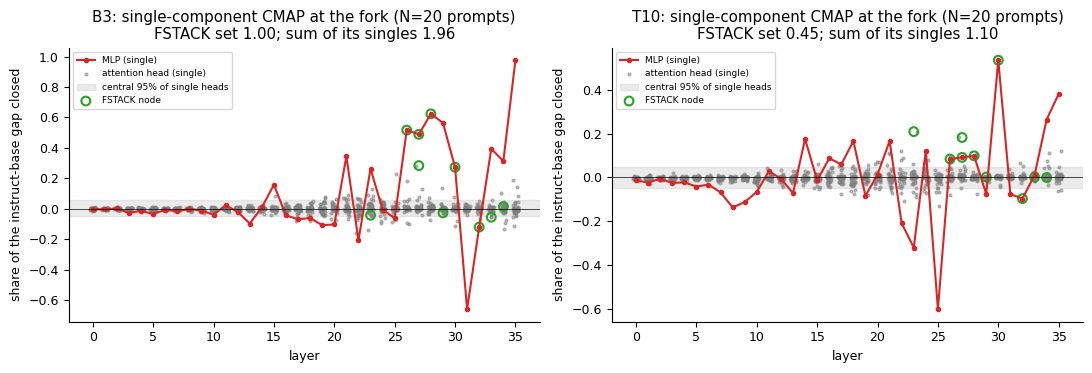

11:44:25|INFO   |figure F3_b2_singles_by_layer


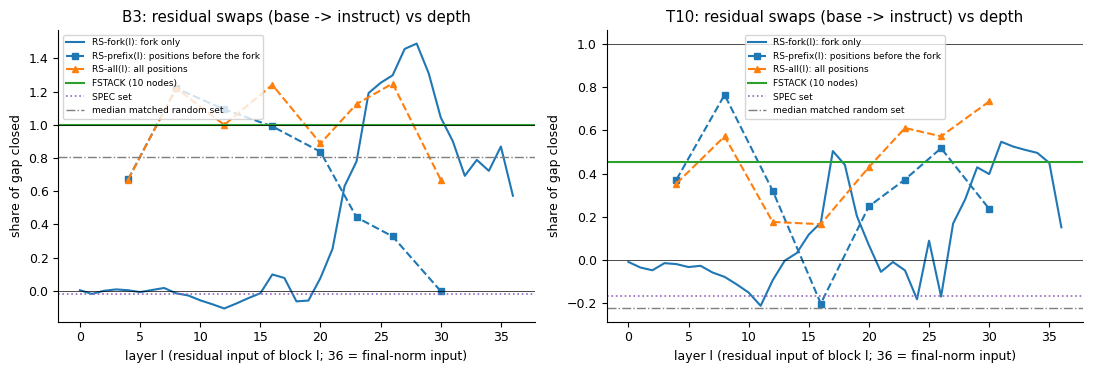

11:44:26|INFO   |figure F4_b2_residual_swaps


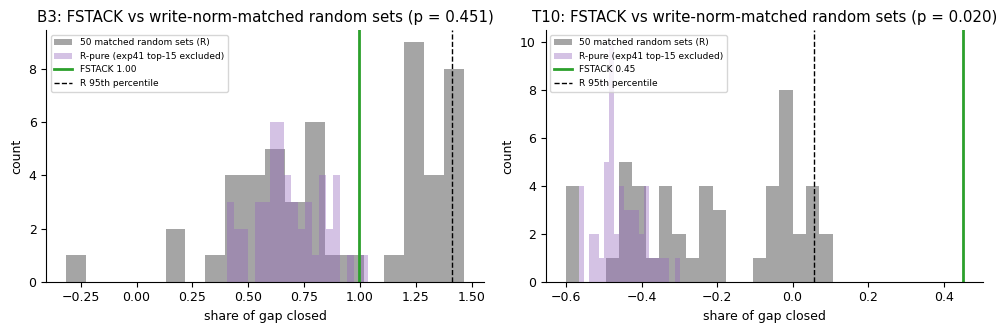

11:44:26|INFO   |figure F5_b2_random_null


In [23]:
b2p = RESULTS_DIR / "b2_summary.json"
if b2p.exists():
    b2_summary = read_json(b2p)
    f3_singles(b2_summary)
    f4_rs(b2_summary)
    f5_null(b2_summary)

## 9. Results: this notebook against the full run

The table puts the numbers computed above next to the ones the full run reported (`results/b2_summary.json`, stored
in the data file under `reported_b2_summary`). At the original Config values the two columns agree. The
unembedding-only share cannot be recomputed here (section 6), so its "this notebook" entry is `None`.

In [24]:
rep = data["metadata"]["reported_b2_summary"]
demo = read_json(RESULTS_DIR / "b2_summary.json")


def _fmt(v):
    if v is None or isinstance(v, (bool, str)):
        return str(v)
    if isinstance(v, (list, tuple)):
        return "[" + ", ".join(f"{x:.2f}" for x in v) + "]"
    return f"{v:.3f}"


def _metrics(r):
    a = r["arms"]
    return {
        "gap m_I - m_B (nats, mean)": r["gap_mean"],
        "gap 95% CI": r["gap_ci95"],
        "FSTACK share": a["FSTACK"]["share"],
        "FSTACK share 95% CI": a["FSTACK"].get("share_ci95"),
        "F_MLP share (its 5 MLPs)": a["F_MLP"]["share"],
        "F_HEAD share (its 5 heads)": a["F_HEAD"]["share"],
        "SPEC share": a["SPEC"]["share"],
        "W_all share (base MLP weights)": a["W_all"]["share"],
        "R null median": r["null_R"]["median"],
        "R null p95": r["null_R"]["p95"],
        "FSTACK p vs R": r["null_R"]["empirical_p_upper"],
        "R-pure null median": r["null_Rpure"]["median"],
        "FSTACK p vs R-pure": r["null_Rpure"]["empirical_p_upper"],
        "RS-fork(23)": r["RS_fork"]["23"],
        "RS-fork(36)": r["RS_fork"]["36"],
        "RS-prefix(23)": r["RS_prefix"]["23"],
        "sum of FSTACK singles": r["sum_singles_FSTACK"],
        "REV: share opened by FSTACK": r["REV"]["share_opened_FSTACK"],
        "Q1 FSTACK >= 0.5": r["Q1"],
        "Q2 FSTACK > R p95 and R median <= 0.15": r["Q2"],
        "Q3 SPEC <= 0.15": r["Q3"],
        "localisation": r["localisation"],
        "unembedding-only share (CPU readout)": (r.get("readout_decomposition_cpu") or {}).get("share_unembedding_only"),
    }


names = list(_metrics(rep["units"]["B3"]))
table = pd.DataFrame({(f"{u} ({data['metadata']['units'][u]['name']})", col): [_fmt(m[k]) for k in names]
                      for u in UNITS
                      for col, m in (("this notebook", _metrics(demo["units"][u])),
                                     ("full run", _metrics(rep["units"][u])))}, index=names)
display(table)
print(f"B2 verdict, this notebook: {demo['verdict']} (Q1 both {demo['Q1_both']}, Q2 both {demo['Q2_both']}, "
      f"Q3 both {demo['Q3_both']})")
print(f"B2 verdict, full run:      {rep['verdict']} (Q1 both {rep['Q1_both']}, Q2 both {rep['Q2_both']}, "
      f"Q3 both {rep['Q3_both']})")
print(f"settings: {N_PROMPTS_PER_UNIT} prompts/unit, N_BOOT {N_BOOT}, N_RAND {N_RAND}, N_RAND_SPEC {N_RAND_SPEC} "
      f"(full run: 20, 10000, 50, 20)")

B3 (MST)                \
                                       this notebook      full run   
gap m_I - m_B (nats, mean)                     2.059         2.059   
gap 95% CI                              [1.96, 2.16]  [1.96, 2.16]   
FSTACK share                                   0.998         0.998   
FSTACK share 95% CI                     [0.96, 1.04]  [0.96, 1.04]   
F_MLP share (its 5 MLPs)                       1.079         1.079   
F_HEAD share (its 5 heads)                     0.174         0.174   
SPEC share                                    -0.019        -0.019   
W_all share (base MLP weights)                 0.227         0.227   
R null median                                  0.807         0.807   
R null p95                                     1.413         1.413   
FSTACK p vs R                                  0.451         0.451   
R-pure null median                             0.656         0.656   
FSTACK p vs R-pure                             0.039         0.039   
RS-fork(23)                                    0.779         0.779   
RS-fork(36)                                    0.573         0.573   
RS-prefix(23)                                  0.443         0.443   
sum of FSTACK singles                          1.958         1.958   
REV: share opened by FSTACK                   -0.304        -0.304   
Q1 FSTACK >= 0.5                                True          True   
Q2 FSTACK > R p95 and R median <= 0.15         False         False   
Q3 SPEC <= 0.15                                 True          True   
localisation                             distributed   distributed   
unembedding-only share (CPU readout)            None         0.426   

                                            T10 (CC)                
                                       this notebook      full run  
gap m_I - m_B (nats, mean)                     4.519         4.519  
gap 95% CI                              [3.50, 5.57]  [3.50, 5.57]  
FSTACK share                                   0.452         0.452  
FSTACK share 95% CI                     [0.28, 0.57]  [0.28, 0.57]  
F_MLP share (its 5 MLPs)                       0.406         0.406  
F_HEAD share (its 5 heads)                     0.302         0.302  
SPEC share                                    -0.167        -0.167  
W_all share (base MLP weights)                 0.383         0.383  
R null median                                 -0.223        -0.223  
R null p95                                     0.056         0.056  
FSTACK p vs R                                  0.020         0.020  
R-pure null median                            -0.461        -0.461  
FSTACK p vs R-pure                             0.020         0.020  
RS-fork(23)                                   -0.047        -0.047  
RS-fork(36)                                    0.152         0.152  
RS-prefix(23)                                  0.372         0.372  
sum of FSTACK singles                          1.102         1.102  
REV: share opened by FSTACK                    0.223         0.223  
Q1 FSTACK >= 0.5                               False         False  
Q2 FSTACK > R p95 and R median <= 0.15          True          True  
Q3 SPEC <= 0.15                                 True          True  
localisation                             distributed   distributed  
unembedding-only share (CPU readout)            None         0.850

B2 verdict, this notebook: PARTIAL (Q1 both False, Q2 both False, Q3 both True)
B2 verdict, full run:      PARTIAL (Q1 both False, Q2 both False, Q3 both True)
settings: 20 prompts/unit, N_BOOT 10000, N_RAND 50, N_RAND_SPEC 20 (full run: 20, 10000, 50, 20)


**The final figure.** The top row shows the per-prompt margins: instruct (m_I), base (m_B), the instruct run after
the FSTACK patch, and after the median random set (the set whose share is the median of the R null, picked as in
F8). The bottom row shows the share of the gap closed by each intervention, with 95% bootstrap CIs where the analysis
computes them. The grey band is the 5th-95th percentile of the R null and the dashed line its median.

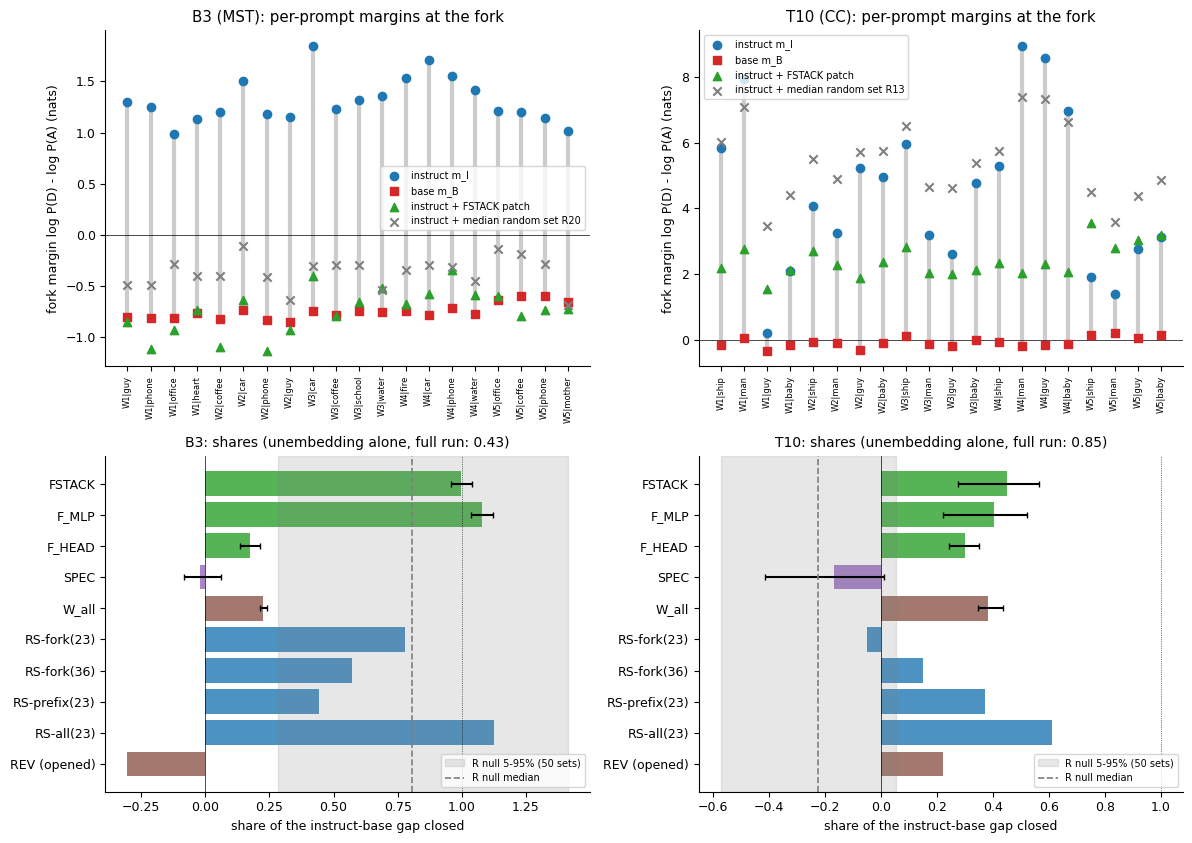

In [25]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8.5))
for col, u in enumerate(UNITS):
    r = demo["units"][u]
    pids, by, mI, mB = rows_by_arm(u)
    rsh = r["null_R"]["shares"]
    med = int(np.argsort(rsh)[len(rsh) // 2])
    x = np.arange(len(pids))
    ax = axes[0, col]
    ax.vlines(x, [mB[p] for p in pids], [mI[p] for p in pids], color="#cccccc", lw=3, zorder=0)
    ax.scatter(x, [mI[p] for p in pids], color=C_I, marker="o", label="instruct m_I", zorder=3)
    ax.scatter(x, [mB[p] for p in pids], color=C_B, marker="s", label="base m_B", zorder=3)
    ax.scatter(x, [by["FSTACK"][p] for p in pids], color=C_F, marker="^", label="instruct + FSTACK patch", zorder=4)
    ax.scatter(x, [by[f"R{med}"][p] for p in pids], color=C_R, marker="x", label=f"instruct + median random set R{med}",
               zorder=4)
    ax.axhline(0, color="k", lw=0.5)
    ax.set_xticks(x)
    ax.set_xticklabels(pids, rotation=90, fontsize=6)
    ax.set_ylabel("fork margin log P(D) - log P(A) (nats)")
    ax.set_title(f"{u} ({data['metadata']['units'][u]['name']}): per-prompt margins at the fork")
    ax.legend(fontsize=7)

    ax = axes[1, col]
    items = [("FSTACK", r["arms"]["FSTACK"]), ("F_MLP", r["arms"]["F_MLP"]), ("F_HEAD", r["arms"]["F_HEAD"]),
             ("SPEC", r["arms"]["SPEC"]), ("W_all", r["arms"]["W_all"]),
             ("RS-fork(23)", {"share": r["RS_fork"]["23"]}), ("RS-fork(36)", {"share": r["RS_fork"]["36"]}),
             ("RS-prefix(23)", {"share": r["RS_prefix"]["23"]}), ("RS-all(23)", {"share": r["RS_all"]["23"]}),
             ("REV (opened)", {"share": r["REV"]["share_opened_FSTACK"]})]
    y = np.arange(len(items))[::-1]
    vals = [it["share"] for _, it in items]
    colors = [C_F if n.startswith("F") else C_S if n == "SPEC" else C_I if n.startswith("RS") else "#8c564b"
              for n, _ in items]
    ax.barh(y, vals, color=colors, alpha=0.8)
    ci = [(yy, it) for yy, (_, it) in zip(y, items) if it.get("share_ci95")]   # bootstrap CIs where computed
    ax.errorbar([it["share"] for _, it in ci], [yy for yy, _ in ci], fmt="none", ecolor="k", capsize=2,
                xerr=[[it["share"] - it["share_ci95"][0] for _, it in ci],
                      [it["share_ci95"][1] - it["share"] for _, it in ci]])
    q5, q95 = np.percentile(rsh, [5, 95])
    ax.axvspan(q5, q95, color=C_R, alpha=0.18, label=f"R null 5-95% ({len(rsh)} sets)")
    ax.axvline(r["null_R"]["median"], color=C_R, ls="--", lw=1.2, label="R null median")
    ax.axvline(0, color="k", lw=0.5)
    ax.axvline(1, color="k", lw=0.5, ls=":")
    ax.set_yticks(y)
    ax.set_yticklabels([n for n, _ in items])
    ax.set_xlabel("share of the instruct-base gap closed")
    une = (rep["units"][u].get("readout_decomposition_cpu") or {}).get("share_unembedding_only")
    ax.set_title(f"{u}: shares (unembedding alone, full run: {une:.2f})", fontsize=10)
    ax.legend(fontsize=7, loc="lower right")
fig.tight_layout()
fig.savefig(FIG_DIR / "summary_b2_demo.png", dpi=150)
plt.show()

## Takeaways and scaling

At the original settings the numbers above reproduce the committed B2 result:

* **MST (B3).** Patching the 10 FSTACK nodes closes essentially the whole 2.06-nat gap (share ≈ 1.00), but matched
  random late-layer sets close a median of ≈ 0.81 (p ≈ 0.45), so Q2 fails. Excluding the components iteration 8 had
  already flagged (R-pure) lowers the null median to ≈ 0.66 (p ≈ 0.04). Several single late MLPs (layers 26-35)
  each close about half the gap: the sharpening is carried **redundantly by late MLPs**.
* **CC (T10).** FSTACK closes only ≈ 0.45 of a 4.5-nat gap, so Q1 fails, although it beats the random sets
  (p ≈ 0.02). In the full run's readout decomposition, the fine-tuned **unembedding alone** accounts for ≈ 85% of the
  CC gap (≈ 43% on MST), which is why even RS-fork(36) stays well below 1.
* **SPEC closes nothing on either unit** (−0.02 on MST, −0.17 on CC), so the preference is not written upstream
  in the task specification (Q3 holds). Verdict **PARTIAL**, with localisation *distributed*.

In terms of the run's question: at this decision token the instruct model's "default answer" is consistent with a
reweighting of the base model's options, applied by the last layers and by the readout, rather than with a new
computation upstream.

**Scaling.** The Config cell already uses the full-run values. Lowering them (for example 2 prompts per unit,
`N_BOOT` = 10, 2 random sets) gives a fast smoke test; the columns then differ from the full run's because fewer
prompts and sets enter. Regenerating the 1,429-arm margin table itself requires the artifact's GPU stages:
`uv run method.py --stages preflight,units,tests,commit0,cache_qwen,patch_qwen`, then
`--stages commit0b,analyze,figures`, with Qwen3-8B and Qwen3-8B-Base on a GPU of 24 GB or more. That takes roughly
20 minutes on an L4, plus the model download; see the artifact's `reproducibility.md`.